# 이미지 임베딩 직접 검색 (CLIP) — 옵션①과 옵션③ 비교

[Multimodal RAG.md](../../Multimodal%20RAG.md)의 "Multimodal RAG 구현 3가지 옵션" 중, 지금까지는 **③번(Multi-Vector Retriever, 요약 임베딩)** 만 다뤘습니다. 이 노트북에서는 **①번(직접 임베딩)** 을 실제로 구현해서, 언제 어느 쪽이 더 잘 맞는지 비교합니다.

- **①번 직접 임베딩**: 캡션 없이 이미지를 곧바로 벡터로 변환 (이번 노트북)
- **③번 요약 임베딩**: `1. Multi-Vector RAG 파이프라인 구축.ipynb`에서 만든 방식 (VLM 요약 → 텍스트 임베딩)

## 사용 모델
텍스트 질의로 이미지를 검색하려면 이미지·텍스트가 **같은 벡터 공간**에 있어야 합니다. 이 노트북에서는 **CLIP**(`sentence-transformers`의 `clip-ViT-B-32` + 다국어 텍스트 인코더 `clip-ViT-B-32-multilingual-v1`)을 사용합니다. 자세한 헬퍼 코드는 `clip_utils.py` 참고.

## 1. 노트북 1과 같은 후보군 불러오기
`1. Multi-Vector RAG 파이프라인 구축.ipynb`에서 만든 `travel_guide_pages` 컬렉션의 메타데이터(이미지 경로, 장소명)를 그대로 재사용합니다. 임베딩 방식만 바꿔서 비교해야 공정한 비교가 되기 때문입니다.

In [1]:
import chromadb

from clip_utils import embed_images, embed_texts

summary_client = chromadb.PersistentClient(path="./chroma_db")
summary_collection = summary_client.get_collection("travel_guide_pages")
summary_docs = summary_collection.get()

doc_ids = summary_docs["ids"]
image_paths = [meta["image_path"] for meta in summary_docs["metadatas"]]
place_names = [doc.splitlines()[1].split(": ")[1].strip() for doc in summary_docs["documents"]]

print(f"{len(doc_ids)}개 페이지 (노트북 1과 동일한 후보군)")
list(zip(doc_ids, place_names))

10개 페이지 (노트북 1과 동일한 후보군)


[('page_03', '국립중앙박물관'),
 ('page_04', '불암산 힐링타운'),
 ('page_05', '서울한방진흥센터'),
 ('page_06', '서울식물원'),
 ('page_07', '여의도한강공원 야외수영장'),
 ('page_09', '국립세계문자박물관'),
 ('page_10', '송도센트럴파크'),
 ('page_11', '송월동동화마을'),
 ('page_12', '옥토끼우주센터'),
 ('page_13', '청라호수공원')]

## 2. 캡션 없이 이미지를 직접 임베딩

`summarize_image`(VLM 호출)를 전혀 쓰지 않고, 페이지 이미지를 CLIP에 바로 넣어 벡터로 변환합니다.

In [2]:
image_embeddings = embed_images(image_paths)

clip_client = chromadb.PersistentClient(path="./chroma_db")
clip_collection = clip_client.get_or_create_collection(
    name="travel_guide_pages_clip",
    metadata={"hnsw:space": "cosine"},
)

# 재실행 시 중복 저장을 막기 위해 기존 항목을 지우고 다시 채운다
clip_collection.delete(ids=doc_ids)
clip_collection.add(
    ids=doc_ids,
    embeddings=image_embeddings,
    metadatas=[
        {"place": place, "image_path": path} for place, path in zip(place_names, image_paths)
    ],
)

print(f"{clip_collection.count()}개 페이지 이미지를 직접 임베딩해 저장했습니다 (캡션 생성 단계 없음).")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

10개 페이지 이미지를 직접 임베딩해 저장했습니다 (캡션 생성 단계 없음).


## 3. 검증: "장소명"으로 검색하면 그 페이지가 1등으로 나올까?

가장 객관적인 정답 기준으로, 각 페이지의 장소명을 그대로 질의로 넣어 자기 자신의 페이지 이미지가 1위로 검색되는지 확인합니다 (10개 중 몇 개나 맞히는지).

In [3]:
correct = 0
for doc_id, place in zip(doc_ids, place_names):
    query_embedding = embed_texts([place])[0]
    result = clip_collection.query(query_embeddings=[query_embedding], n_results=1)
    top_place = result["metadatas"][0][0]["place"]
    hit = result["ids"][0][0] == doc_id
    correct += hit
    print(f"질의='{place}' -> 1위 검색결과='{top_place}'  {'OK' if hit else 'MISS'}")

print(f"\n정확도: {correct}/{len(doc_ids)}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

질의='국립중앙박물관' -> 1위 검색결과='서울한방진흥센터'  MISS
질의='불암산 힐링타운' -> 1위 검색결과='불암산 힐링타운'  OK
질의='서울한방진흥센터' -> 1위 검색결과='서울한방진흥센터'  OK
질의='서울식물원' -> 1위 검색결과='국립세계문자박물관'  MISS
질의='여의도한강공원 야외수영장' -> 1위 검색결과='국립세계문자박물관'  MISS
질의='국립세계문자박물관' -> 1위 검색결과='국립중앙박물관'  MISS
질의='송도센트럴파크' -> 1위 검색결과='국립세계문자박물관'  MISS
질의='송월동동화마을' -> 1위 검색결과='송월동동화마을'  OK
질의='옥토끼우주센터' -> 1위 검색결과='국립세계문자박물관'  MISS
질의='청라호수공원' -> 1위 검색결과='국립세계문자박물관'  MISS

정확도: 3/10


10개 중 3개만 맞고 나머지는 엉뚱한 페이지가 1위로 나옵니다 — 무작위(10개 중 1개꼴)보다 살짝 나은 수준일 뿐입니다. CLIP이 "이미지를 이해하지 못해서"가 아니라, 이 페이지들이 CLIP이 학습한 데이터(사진-캡션 쌍)와 성격이 다르기 때문입니다 — 페이지 대부분이 문단 텍스트(주소, 운영시간, "휠체어 접근 가능" 등)로 빽빽하고, CLIP은 사진 속에 적힌 글자를 세밀하게 "읽는" 능력이 약합니다. VLM 요약(옵션③)은 VLM이 이미지를 실제로 읽고 요약하기 때문에 이런 세부 텍스트까지 검색에 반영됩니다 — 이 강의가 PDF 검색에 옵션③을 택한 이유입니다.

그럼 CLIP 직접 임베딩은 언제 쓸모가 있을까요? 아래에서 문서 페이지가 아닌 **사진이 주인공인 PDF**로 같은 실험을 반복해봅니다.

## 4. 사진 위주 PDF로 같은 파이프라인 반복하기

이번엔 진짜 "사진이 주인공인 PDF"로 노트북 1과 **완전히 동일한 파이프라인**(PDF → 페이지 렌더링 → 임베딩 → 질의)을 반복합니다.

`data/food_photo_catalog.pdf`는 `1. Image Embedding`에서 이미 쓰고 있는 피자·스테이크·초밥 사진 15장(각 5장)을 그대로 페이지로 담은 PDF입니다. 페이지 안에는 페이지 번호 말고는 텍스트가 없습니다.

In [4]:
from pathlib import Path

import fitz  # PyMuPDF, 노트북 1과 동일하게 페이지를 이미지로 렌더링

FOOD_PDF_PATH = Path("./data/food_photo_catalog.pdf")
FOOD_PAGE_DIR = Path("./pages/food_photo_catalog")
FOOD_PAGE_DIR.mkdir(parents=True, exist_ok=True)

food_doc = fitz.open(FOOD_PDF_PATH)
# PDF를 만들 때 pizza 5장 -> steak 5장 -> sushi 5장 순으로 넣었다
# (정답 확인용, PDF 안에는 없는 정보. detail은 5번 섹션의 조합 질의에서 사용)
food_categories = ["pizza"] * 5 + ["steak"] * 5 + ["sushi"] * 5
food_details = (
    ["-"] * 5
    + ["감튀있음", "감튀없음", "감튀없음", "감튀없음", "감튀없음"]
    + ["니기리만", "롤만", "롤만", "롤+니기리", "롤+니기리"]
)

food_ids, food_paths, food_labels, food_detail_labels = [], [], [], []
for i, page in enumerate(food_doc):
    pix = page.get_pixmap(dpi=150)
    image_path = FOOD_PAGE_DIR / f"page_{i:02d}.png"
    pix.save(image_path)
    food_ids.append(f"page_{i:02d}")
    food_paths.append(str(image_path))
    food_labels.append(food_categories[i])
    food_detail_labels.append(food_details[i])

print(f"{len(food_paths)}페이지를 이미지로 렌더링했습니다 (텍스트 없음).")

15페이지를 이미지로 렌더링했습니다 (텍스트 없음).


In [5]:
food_embeddings = embed_images(food_paths)

food_client = chromadb.PersistentClient(path="./chroma_db")
food_collection = food_client.get_or_create_collection(
    name="food_catalog_pages_clip",
    metadata={"hnsw:space": "cosine"},
)
food_collection.delete(ids=food_ids)
food_collection.add(
    ids=food_ids,
    embeddings=food_embeddings,
    metadatas=[
        {"category": cat, "detail": detail, "image_path": path}
        for cat, detail, path in zip(food_labels, food_detail_labels, food_paths)
    ],
)

print(f"{food_collection.count()}개 페이지를 캡션 없이 직접 임베딩했습니다 (VLM 호출 없음).")

15개 페이지를 캡션 없이 직접 임베딩했습니다 (VLM 호출 없음).


In [6]:
queries = {
    "pizza": "치즈가 잔뜩 올라간 동그란 빵 요리",
    "steak": "잘 구운 두툼한 고기 요리",
    "sushi": "생선회를 올린 초밥",
}

for expected_cat, query in queries.items():
    query_embedding = embed_texts([query])[0]
    result = food_collection.query(query_embeddings=[query_embedding], n_results=5)
    top5_cats = [m["category"] for m in result["metadatas"][0]]
    acc = top5_cats.count(expected_cat) / len(top5_cats)
    print(f"질의='{query}' (정답 카테고리: {expected_cat})")
    print(f"  top5={top5_cats}  (정답 비율 {acc:.0%})\n")

질의='치즈가 잔뜩 올라간 동그란 빵 요리' (정답 카테고리: pizza)
  top5=['pizza', 'pizza', 'pizza', 'steak', 'steak']  (정답 비율 60%)

질의='잘 구운 두툼한 고기 요리' (정답 카테고리: steak)
  top5=['steak', 'steak', 'steak', 'steak', 'steak']  (정답 비율 100%)

질의='생선회를 올린 초밥' (정답 카테고리: sushi)
  top5=['sushi', 'sushi', 'sushi', 'steak', 'sushi']  (정답 비율 80%)



질의: 치즈가 잔뜩 올라간 동그란 빵 요리
1위 검색 결과: pages\food_photo_catalog\page_03.png (카테고리: pizza)


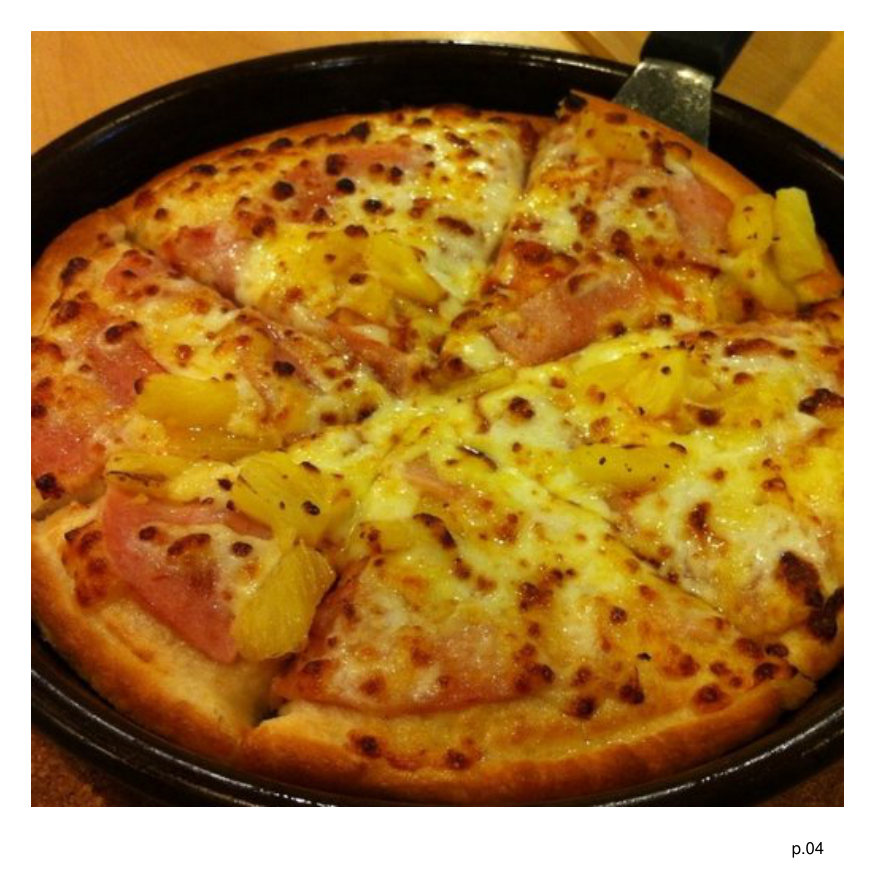

In [7]:
from rag_utils import show

query = "치즈가 잔뜩 올라간 동그란 빵 요리"
query_embedding = embed_texts([query])[0]
result = food_collection.query(query_embeddings=[query_embedding], n_results=1)
top_meta = result["metadatas"][0][0]

print(f"질의: {query}")
print(f"1위 검색 결과: {top_meta['image_path']} (카테고리: {top_meta['category']})")
show(top_meta["image_path"])

카테고리 수준의 질의는 잘 됩니다 (피자 60%, 스테이크 100%, 초밥 80%). 캡션 생성 없이도 "이 사진이 피자냐 스테이크냐 초밥이냐"는 CLIP이 꽤 잘 구분합니다.

그런데 "감자튀김과 함께 있는 스테이크"처럼, 같은 카테고리 안에서 **부가 요소의 유무**를 구분해야 하는 질의는 어떨까요?

## 5. 조합 질의는 어떨까?

같은 스테이크 사진 5장 중에는 감자튀김이 있는 것도, 없는 것도 있습니다. 같은 초밥 사진 5장 중에는 롤만 있는 것, 니기리만 있는 것, 롤과 니기리가 함께 있는 것이 섞여 있습니다. "감자튀김과 함께 있는 스테이크", "롤과 니기리가 함께 있는 초밥"처럼 **같은 카테고리 안에서 부가 요소의 조합**을 구분해야 하는 질의를 테스트해봅니다.

In [8]:
compositional_queries = {
    "감자튀김과 함께 있는 스테이크 사진": ("steak", "감튀있음"),
    "롤과 니기리가 함께 있는 초밥 사진": ("sushi", "롤+니기리"),
}

for query, (cat, detail) in compositional_queries.items():
    query_embedding = embed_texts([query])[0]
    result = food_collection.query(query_embeddings=[query_embedding], n_results=len(food_ids))
    ranked = [(m["category"], m["detail"]) for m in result["metadatas"][0]]
    rank = next(i for i, (c, d) in enumerate(ranked) if c == cat and d == detail) + 1
    print(f"질의='{query}'")
    print(f"  정답 사진의 순위: {rank}위 / {len(food_ids)}장 중")
    print(f"  1위로 뽑힌 사진의 카테고리·특징: {ranked[0]}\n")

질의='감자튀김과 함께 있는 스테이크 사진'
  정답 사진의 순위: 3위 / 15장 중
  1위로 뽑힌 사진의 카테고리·특징: ('steak', '감튀없음')

질의='롤과 니기리가 함께 있는 초밥 사진'
  정답 사진의 순위: 4위 / 15장 중
  1위로 뽑힌 사진의 카테고리·특징: ('sushi', '롤만')



카테고리 수준 질의(60~100%)와 달리, 정답 사진이 1위로 나오지 않습니다 (감자튀김 스테이크는 15장 중 3위, 롤+니기리 초밥은 4위 — 오히려 부가 요소가 없는 사진이 1위로 뽑힙니다). CLIP은 이미지 전체의 "느낌"을 하나의 벡터로 뭉뚱그리기 때문에, 같은 카테고리 안에서 "이 부가 요소가 있다/없다"는 조합 정보는 벡터에 잘 반영되지 않습니다.

그럼 이런 조합 질의는 어떻게 정확히 처리할 수 있을까요?

## 6. CLIP(검색) + VLM(검증) 2단계로 해결하기

실무에서는 보통 2단계로 처리합니다.

1. **CLIP으로 후보를 좁힌다**: "스테이크" 같은 큰 카테고리는 CLIP이 잘 구분하므로, 전체 이미지가 아니라 상위 후보 몇 장으로 줄인다.
2. **VLM으로 후보를 검증한다**: 좁혀진 후보 각각에 VLM으로 "감자튀김이 있는지" 같은 세부 조건을 직접 물어본다.

이렇게 하면 VLM을 전체 이미지에 다 돌릴 필요 없이(비용 절감) 조합 조건도 정확히 걸러낼 수 있습니다. VLM에게 질문할 때는 바로 "예/아니오"만 묻기보다, **먼저 사진을 설명하게 한 뒤 마지막에 답하게 하면** 배경의 작은 요소도 잘 놓치지 않습니다 (`2. VLM Prompt Engineering`에서 다룬 내용과 같은 원리).

In [9]:
from rag_utils import ask_vlm

# 1단계: CLIP으로 "스테이크" 후보만 좁힌다
category_embedding = embed_texts(["잘 구운 두툼한 고기 요리"])[0]
candidates = food_collection.query(query_embeddings=[category_embedding], n_results=5)

# 2단계: 후보마다 VLM에게 조건을 직접 검증한다 (먼저 설명 -> 마지막에 판정)
verify_prompt = (
    "이 사진을 설명해줘. 접시들 중에 감자튀김(프렌치프라이)이 있는지도 알려주고, "
    "마지막 줄에 '정답: 예' 또는 '정답: 아니오'로 답해줘."
)

print("질의: 감자튀김과 함께 있는 스테이크 사진\n")
answer_path = None
for meta in candidates["metadatas"][0]:
    verdict = ask_vlm(verify_prompt, image_paths=[meta["image_path"]])
    is_yes = verdict.strip().splitlines()[-1].endswith("예")
    print(f"{meta['image_path']} -> {'예' if is_yes else '아니오'}")
    if is_yes and answer_path is None:
        answer_path = meta["image_path"]

print(f"\n최종 정답: {answer_path}")

질의: 감자튀김과 함께 있는 스테이크 사진



pages\food_photo_catalog\page_08.png -> 아니오


pages\food_photo_catalog\page_06.png -> 아니오


pages\food_photo_catalog\page_09.png -> 아니오


pages\food_photo_catalog\page_07.png -> 아니오


pages\food_photo_catalog\page_05.png -> 예

최종 정답: pages\food_photo_catalog\page_05.png


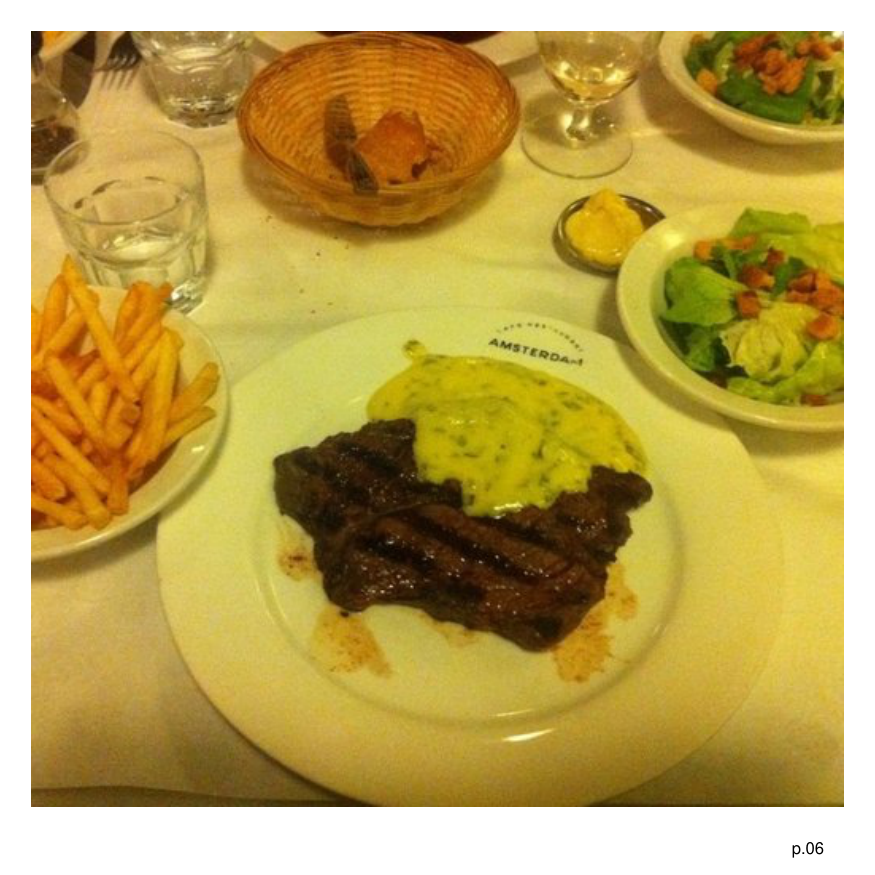

In [10]:
show(answer_path)

CLIP만으로는 실패했던 조합 질의가, CLIP(후보 좁히기) + VLM(세부 검증) 2단계로는 정확히 처리됩니다.

## 정리: 이미지 검색에 CLIP과 VLM을 어떻게 나눠 쓸까?

| 질의 유형 | 적합한 방식 | 이유 |
|---|---|---|
| 카테고리 하나 구분 (피자/스테이크/초밥, 은하/성운/행성 등) | CLIP 임베딩만으로 충분 | 이미지 전체의 시각적 유사도로 판단 가능 |
| 부가 요소의 조합/포함 여부 (감자튀김이 있는지, 롤+니기리가 함께 있는지) | CLIP(후보 좁히기) + VLM(검증) | CLIP은 이미지를 하나의 벡터로 뭉뚱그려 세부 조합을 못 잡음. VLM이 직접 봐야 정확함 |
| 텍스트가 빽빽한 문서/스캔 이미지 (PDF 페이지, 표, 슬라이드) | VLM 요약 임베딩 (Multi-Vector, 옵션③) | CLIP은 이미지 속 세부 텍스트를 "읽는" 능력이 약함 |
| 영상 (`4. Video Language Model`) | VLM 요약 임베딩 (옵션③) | 프레임 수가 많아 프레임마다 직접 임베딩하면 비용이 급증 — 클립 단위 요약 1개만 임베딩하는 게 효율적 |

> 이 "CLIP으로 후보를 좁히고 VLM으로 검증/재정렬한다"는 패턴은 [Multimodal RAG.md](../../Multimodal%20RAG.md)의 Hybrid Search와 같은 아이디어입니다 — 텍스트 임베딩 검색과 이미지 임베딩 검색을 결합하는 대신, 여기서는 이미지 임베딩과 VLM 검증을 결합한 것입니다.

## 7. 실무에서는 이미지 임베딩을 언제, 어떻게 쓸까?

이 노트북에서 살펴본 결과를 실무 사례에 대입해보면 패턴이 보입니다.

**CLIP 임베딩만으로 잘 맞는 실무 사례**
- **시각적 유사도 검색**: Pinterest Lens, 무신사·지그재그의 "이 옷과 비슷한 상품 찾기", 스톡 사진 사이트의 자연어 이미지 검색 — 상품·사진처럼 세계적으로 흔한 피사체 + 카테고리 수준 유사도가 목적
- **얼굴 인식/클러스터링**: 구글 포토·아이폰 사진 앱의 "이 사람 나온 사진 모아보기" (CLIP은 아니지만 원리는 동일한 임베딩 유사도 검색)
- **중복·도용 탐지, 콘텐츠 모더레이션**: 재업로드된 영상/이미지 탐지, 유해 이미지 필터링

**CLIP + VLM을 함께 써야 하는 실무 사례**
- **세밀한 속성/조합 조건이 있는 상품 검색**: "이 드레스랑 비슷한데 소매가 긴 것", "이 가방이랑 비슷한데 지퍼가 있는 것" — 카테고리는 CLIP으로 좁히고, 속성 조건은 VLM으로 검증
- **콘텐츠 추천의 세부 필터링**: 카테고리(음식/여행/뷰티)는 임베딩으로 후보를 뽑고, "아이가 나오는 사진 제외" 같은 세부 조건은 VLM이 재검토

**이미지 임베딩만으로는 부족한 실무 사례**
- **문서/스캔 이미지 검색**: 계약서·보고서·슬라이드처럼 텍스트가 정보의 핵심인 경우 — 앞서 본 여행 가이드북이 정확히 이 케이스입니다. VLM 캡션(옵션③)이나 OCR이 필요합니다.
- **니치·전문 도메인**: 의료 영상(피부 병변 유사 사례 검색), 제조업 불량품 탐지처럼 웹에 흔하지 않은 대상은 기성 CLIP을 그대로 쓰지 않고, 자기 데이터로 **임베딩 모델을 파인튜닝**해서 씁니다.

즉 "이미지 임베딩이 필요한가?"의 답은 **① 시각적 유사도 자체가 목적이고, ② 이미지 속 텍스트를 읽을 필요가 없고, ③ 그 피사체가 (기성 모델 기준으로) 흔할 때**입니다. 다만 ①~③을 만족해도 **세밀한 속성/조합 조건**이 걸리면 CLIP 단독으로는 부족하고, VLM 검증 단계를 더해야 합니다.